<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_11/dataset_pbl/praktikum_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM 4 - PENYESUAIAN DATASET**
## **Langkah 0 - Memuat Dataset Baru**
Dataset yang digunakan adalah `Sleep_health_and_lifestyle_dataset.csv`.



In [17]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv('/content/Sleep_health_and_lifestyle_dataset.csv')
display(df.head())
print(df.info())

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB
None


## **Langkah 1 - Pra Pengolahan Data (Preprocessing)**
Kita perlu menangani nilai kosong pada target `Sleep Disorder` (mengisinya dengan 'None' jika tidak ada gangguan tidur), melakukan encoding pada fitur kategorikal, serta memisahkan fitur dan target.


In [18]:
# Mengisi nilai kosong pada target Sleep Disorder
df['Sleep Disorder'] = df['Sleep Disorder'].fillna('None')

# Encoding kolom kategorikal
from sklearn.preprocessing import LabelEncoder

le_gender = LabelEncoder()
df['Gender'] = le_gender.fit_transform(df['Gender'])

le_occ = LabelEncoder()
df['Occupation'] = le_occ.fit_transform(df['Occupation'])

# Memecah Blood Pressure menjadi Systolic dan Diastolic
df[['Systolic_BP', 'Diastolic_BP']] = df['Blood Pressure'].str.split('/', expand=True).astype(int)
df = df.drop(columns=['Blood Pressure', 'Person ID'])

# Encoding BMI Category
le_bmi = LabelEncoder()
df['BMI Category'] = le_bmi.fit_transform(df['BMI Category'])

# Encoding Target (Sleep Disorder)
le_target = LabelEncoder()
df['Sleep Disorder'] = le_target.fit_transform(df['Sleep Disorder'])

target_names = le_target.classes_
print("Target Classes:", target_names)
display(df.head())

Target Classes: ['Insomnia' 'None' 'Sleep Apnea']


,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic_BP,Diastolic_BP
0,1,27,9,6.1,6,42,6,3,77,4200,1,126,83
1,1,28,1,6.2,6,60,8,0,75,10000,1,125,80
2,1,28,1,6.2,6,60,8,0,75,10000,1,125,80
3,1,28,6,5.9,4,30,8,2,85,3000,2,140,90
4,1,28,6,5.9,4,30,8,2,85,3000,2,140,90


## **Langkah 2 - Split Data**


In [19]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Sleep Disorder'])
y = df['Sleep Disorder']

Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

## **Langkah 3 - Pembuatan Pipeline (PCA + SVC)**


In [20]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Standarisasi fitur sebelum PCA & SVC
scaler = StandardScaler()
pca = PCA(n_components=5, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')

model = make_pipeline(scaler, pca, svc)

## **Langkah 4 - Tuning Hyperparameter dengan GridSearch**


In [21]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'svc__C': [1, 5, 10, 50],
    'svc__gamma': [0.001, 0.01, 0.1, 1]
}
grid = GridSearchCV(model, param_grid, cv=5)

%time grid.fit(Xtrain, ytrain)
print("Best Params:", grid.best_params_)
print("Best CV Score:", grid.best_score_)

CPU times: user 934 ms, sys: 4.08 ms, total: 938 ms
Wall time: 940 ms
Best Params: {'svc__C': 1, 'svc__gamma': 1}
Best CV Score: 0.876271186440678


## **Langkah 5 - Evaluasi Model**


              precision    recall  f1-score   support

    Insomnia       0.93      0.87      0.90        15
        None       0.93      0.98      0.96        44
 Sleep Apnea       0.87      0.81      0.84        16

    accuracy                           0.92        75
   macro avg       0.91      0.89      0.90        75
weighted avg       0.92      0.92      0.92        75



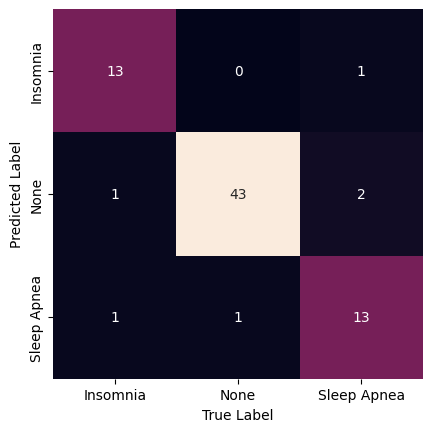

In [22]:
best_model = grid.best_estimator_
yfit = best_model.predict(Xtest)

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

print(classification_report(ytest, yfit, target_names=target_names))

mat = confusion_matrix(ytest, yfit)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=target_names,
            yticklabels=target_names)
plt.xlabel('True Label')
plt.ylabel('Predicted Label')
plt.show()

# **PRAKTIKUM 4**
## **Langkah 0 - Memuat Dataset Sleep Health**
Dataset ini memuat data kesehatan tidur dan gaya hidup seseorang.


In [23]:
import pandas as pd
import numpy as np

df = pd.read_csv('/content/Sleep_health_and_lifestyle_dataset.csv')
display(df.head())

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


## **Langkah 1 - Pra Pengolahan Data**
Kita akan melakukan pembersihan nilai kosong pada target `Sleep Disorder`, melakukan encoding kategori, dan rekayasa fitur sederhana.


In [24]:
from sklearn.preprocessing import LabelEncoder

# Mengisi nilai kosong
df['Sleep Disorder'] = df['Sleep Disorder'].fillna('None')

# Label Encoding untuk kolom kategorikal
for col in ['Gender', 'Occupation', 'BMI Category']:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])

# Memecah Blood Pressure
df[['Systolic_BP', 'Diastolic_BP']] = df['Blood Pressure'].str.split('/', expand=True).astype(int)
df = df.drop(columns=['Blood Pressure', 'Person ID'])

# Encoding Target
le_target = LabelEncoder()
df['Sleep Disorder'] = le_target.fit_transform(df['Sleep Disorder'])
target_names = le_target.classes_

display(df.head())

,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic_BP,Diastolic_BP
0,1,27,9,6.1,6,42,6,3,77,4200,1,126,83
1,1,28,1,6.2,6,60,8,0,75,10000,1,125,80
2,1,28,1,6.2,6,60,8,0,75,10000,1,125,80
3,1,28,6,5.9,4,30,8,2,85,3000,2,140,90
4,1,28,6,5.9,4,30,8,2,85,3000,2,140,90


## **Langkah 2 - Pipeline Klasifikasi (PCA + SVC)**
Kita membangun pipeline pengolahan data menggunakan StandardScaler, PCA untuk reduksi dimensi, dan Support Vector Classifier (SVC).


In [25]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
pca = PCA(n_components=5, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')

model = make_pipeline(scaler, pca, svc)

## **Langkah 3 - Pemisahan Data (Split Data)**


In [26]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Sleep Disorder'])
y = df['Sleep Disorder']

Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

## **Langkah 4 - Pembuatan Model & Hyperparameter Tuning dengan GridSearchCV**


In [27]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'svc__C': [1, 5, 10, 50],
    'svc__gamma': [0.001, 0.01, 0.1, 1]
}
grid = GridSearchCV(model, param_grid, cv=5)

%time grid.fit(Xtrain, ytrain)
print("Parameters terbaik:", grid.best_params_)
print("Akurasi terbaik di CV:", grid.best_score_)

CPU times: user 951 ms, sys: 1.08 ms, total: 952 ms
Wall time: 953 ms
Parameters terbaik: {'svc__C': 1, 'svc__gamma': 1}
Akurasi terbaik di CV: 0.876271186440678


In [28]:
best_model = grid.best_estimator_
yfit = best_model.predict(Xtest)

## **Langkah 5 - Cek Hasil Prediksi Sampel**
Berikut visualisasi sampel nilai asli dan hasil klasifikasinya.


In [29]:
# Menampilkan perbandingan 15 data uji pertama
sample_comparison = pd.DataFrame({
    'Sebenarnya': le_target.inverse_transform(ytest[:15]),
    'Prediksi': le_target.inverse_transform(yfit[:15])
})
display(sample_comparison)

,Sebenarnya,Prediksi
0,Insomnia,Insomnia
1,Insomnia,Insomnia
2,Sleep Apnea,Sleep Apnea
3,Sleep Apnea,Sleep Apnea
4,Insomnia,Insomnia
5,None,None
6,None,None
7,Insomnia,Insomnia
8,Sleep Apnea,Sleep Apnea
9,None,None


## **Langkah 6 - Evaluasi Performa**
Kita mengevaluasi performa model menggunakan Classification Report dan Confusion Matrix.


In [30]:
from sklearn.metrics import classification_report
print(classification_report(ytest, yfit, target_names=target_names))

              precision    recall  f1-score   support

    Insomnia       0.93      0.87      0.90        15
        None       0.93      0.98      0.96        44
 Sleep Apnea       0.87      0.81      0.84        16

    accuracy                           0.92        75
   macro avg       0.91      0.89      0.90        75
weighted avg       0.92      0.92      0.92        75



Dari tabel tersebut, kita mendapatkan informasi terkait dengan akurasi keseluruhan, presisi, recall, dan f1-score untuk setiap label.

Selanjutnya, kita dapat menggunakan confusion matrix untuk mengetahui label label yang terklasifikasi  dengan benar dan tidak.

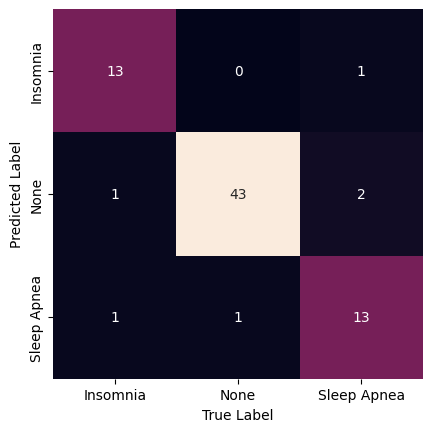

In [31]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

mat = confusion_matrix(ytest, yfit)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=target_names,
            yticklabels=target_names)
plt.xlabel('True Label')
plt.ylabel('Predicted Label')
plt.show()